In [1]:
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub

# Download latest version
path = kagglehub.dataset_download("gregorut/videogamesales")

print("Path to dataset files:", path)

/kaggle/input/videogamesales/vgsales.csv
Path to dataset files: /kaggle/input/videogamesales


# Predict video game sales (Regression)

**Understand the Problem**

Define the task: Is it regression (predicting continuous values) or classification (predicting discrete labels)?
Ensure data contains input features (predictors) and target variable.

In [2]:
# Import helpful libraries
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

# Load the data, and separate the target
video_game_file_path = '/kaggle/input/videogamesales/vgsales.csv'
video_game_data = pd.read_csv(video_game_file_path)

#Feature Selection: Eliminate irrelevant features to improve model efficiency

# Define target variable
y = video_game_data['Global_Sales']

# Create X with set of features
features = ['Genre', 'Publisher', 'Year', 'Rank', 'NA_Sales','JP_Sales', 'EU_Sales']
X = video_game_data[features]

#Train-Test Split: Split data into training and validation sets. 

X_train, X_valid, y_train, y_valid = train_test_split(X, y, random_state=1)

## 2. Data Preprocessing

In [3]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# function for comparing different approaches
def score_dataset(X_train, X_valid, y_train, y_valid):
    model = RandomForestRegressor(n_estimators=100, random_state=0)
    model.fit(X_train, y_train)
    preds = model.predict(X_valid)
    return mean_absolute_error(y_valid, preds)

In [4]:
# Get names of columns with missing values
cols_with_missing = [col for col in X_train.columns
                     if X_train[col].isnull().any()]

# Drop columns in training and validation data
X_train = X_train.drop(cols_with_missing, axis=1)
X_valid = X_valid.drop(cols_with_missing, axis=1)

In [5]:
# Apply OneHotEncoder for categorical features
from sklearn.preprocessing import OneHotEncoder

object_cols = [col for col in X_train.columns if X_train[col].dtype == 'object']

# Apply one-hot encoder to each column with categorical data
OH_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
OH_cols_train = pd.DataFrame(OH_encoder.fit_transform(X_train[object_cols]))
OH_cols_valid = pd.DataFrame(OH_encoder.transform(X_valid[object_cols]))

# One-hot encoding removed index; put it back
OH_cols_train.index = X_train.index
OH_cols_valid.index = X_valid.index

# Remove categorical columns (will replace with one-hot encoding)
num_X_train = X_train.drop(object_cols, axis=1)
num_X_valid = X_valid.drop(object_cols, axis=1)

# Add one-hot encoded columns to numerical features
X_train = pd.concat([num_X_train, OH_cols_train], axis=1)
X_valid = pd.concat([num_X_valid, OH_cols_valid], axis=1)

# Ensure all columns have string type
X_train.columns = X_train.columns.astype(str)
X_valid.columns = X_valid.columns.astype(str)

print("One-Hot Encoding:") 
print(score_dataset(X_train, X_valid, y_train, y_valid))

One-Hot Encoding:
0.002058457831325595


## 3. Model Building & Training

In [6]:
# Select the model: Decision tree/Random Forest for regression or classification.
# Specify hyper parameters relevant to model: e.g. max_depth: Controls tree depth, n_estimators etc. 
# Fit on training data
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

# Random forest model
rt_vg_model = RandomForestRegressor(random_state=1)
rt_vg_model.fit(X_train, y_train)

# # Decision tree model
dt_vg_model = DecisionTreeRegressor(random_state=1)
dt_vg_model.fit(X_train, y_train)

DecisionTreeRegressor(random_state=1)

In [7]:
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Assuming X_train_final and X_valid_final are your features, and y_train and y_valid are your target

# Initialize SimpleImputer
imputer = SimpleImputer(strategy='mean')  # You can use 'median' or 'most_frequent' if needed

# Fit and transform on training data
X_train_imputed = pd.DataFrame(imputer.fit_transform(X_train))
X_valid_imputed = pd.DataFrame(imputer.transform(X_valid))

# Reassign column names after imputation (as imputation can remove them)
X_train_imputed.columns = X_train.columns
X_valid_imputed.columns = X_valid.columns

# Now, you can train the model
rt_vg_model = RandomForestRegressor(random_state=1)
rt_vg_model.fit(X_train_imputed, y_train)

# Make predictions
y_train_pred = rt_vg_model.predict(X_train_imputed)
y_valid_pred = rt_vg_model.predict(X_valid_imputed)

# Evaluate the model
train_mae = mean_absolute_error(y_train, y_train_pred)
valid_mae = mean_absolute_error(y_valid, y_valid_pred)

print(f"Training MAE: {train_mae:.2f}")
print(f"Validation MAE: {valid_mae:.2f}")

Training MAE: 0.00
Validation MAE: 0.00


## 4. Model Evaluation - Evaluate on the training and validation data

In [8]:
from sklearn.metrics import mean_absolute_error
def get_mae(max_leaf_nodes, X_train, X_valid, y_train, y_valid):
    dt_vg_model = DecisionTreeRegressor(max_leaf_nodes=max_leaf_nodes, random_state=0)
    dt_vg_model.fit(X_train, y_train)
    preds_val = dt_vg_model.predict(X_valid)
    mae = mean_absolute_error(y_valid, preds_val)
    return(mae)

vg_val_predictions = rt_vg_model.predict(X_valid)
vg_val_mae = mean_absolute_error(vg_val_predictions, y_valid)
print(vg_val_mae)

for max_leaf_nodes in [5, 50, 500, 5000]:
    my_mae = get_mae(max_leaf_nodes, X_train, X_valid, y_train, y_valid)
    print("Max leaf nodes: %d  \t\t Mean Absolute Error:  %d" %(max_leaf_nodes, my_mae))

# For Regression: Metrics: Mean Absolute Error (MAE)
# Comment on whether your model is underfitting or overfitting or not.

0.002782867469879818
Max leaf nodes: 5  		 Mean Absolute Error:  0
Max leaf nodes: 50  		 Mean Absolute Error:  0
Max leaf nodes: 500  		 Mean Absolute Error:  0
Max leaf nodes: 5000  		 Mean Absolute Error:  0


In [9]:
# from sklearn.tree import DecisionTreeRegressor

# Optionally, make predictions and evaluate the models
rt_vg_predictions = rt_vg_model.predict(X_valid)

# Fit the model with best_tree_size
final_model = DecisionTreeRegressor(max_leaf_nodes=50, random_state=1)

# fit the final model
final_model.fit(X_train, y_train)

# Evaluation using Mean Absolute Error

rt_vg_mae = mean_absolute_error(y_valid, rt_vg_predictions)
#dt_vg_mae = mean_absolute_error(y_valid, dt_vg_predictions)

print(f"Random Forest Model MAE: {rt_vg_mae:.2f}")
#print(f"Decision Tree Model MAE: {dt_vg_mae:.2f}")

Random Forest Model MAE: 0.00


In [10]:
#Target variable distribution
print(y_train.describe())
print(y_valid.describe())

# Compare a sample of predictions with actual values
print("Sample Predictions vs Actuals:")
print(f"Predictions: {rt_vg_predictions[:10]}")
print(f"Actuals: {y_valid[:10]}")

count    12448.000000
mean         0.539590
std          1.611016
min          0.010000
25%          0.060000
50%          0.170000
75%          0.470000
max         82.740000
Name: Global_Sales, dtype: float64
count    4150.000000
mean        0.530993
std         1.373629
min         0.010000
25%         0.060000
50%         0.170000
75%         0.477500
max        31.370000
Name: Global_Sales, dtype: float64
Sample Predictions vs Actuals:
Predictions: [0.46  0.23  7.251 0.36  0.04  0.08  0.15  0.56  0.1   0.36 ]
Actuals: 4234     0.46
7119     0.23
106      7.13
5242     0.36
13547    0.04
11608    0.08
8750     0.15
3603     0.56
10652    0.10
5190     0.36
Name: Global_Sales, dtype: float64


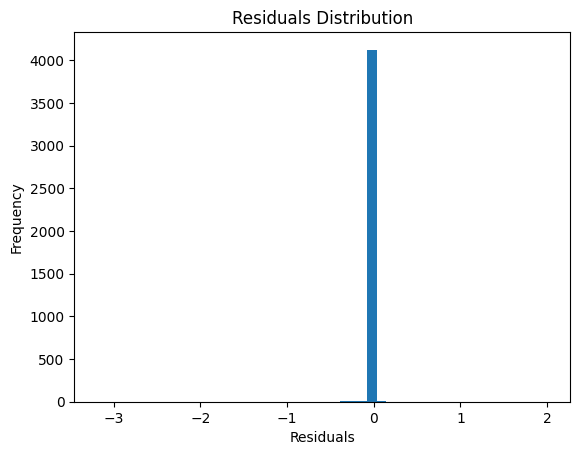

In [11]:
residuals = y_valid - rt_vg_predictions
plt.hist(residuals, bins=50)
plt.title("Residuals Distribution")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

## 5. Model Interpretation